In [1]:
%pip install -e $HOME/opt/tapioca

Obtaining file:///home/jobueno/opt/tapioca
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tapioca-mandyoc (pyproject.toml) ... done
  Created wheel for tapioca-mandyoc: filename=tapioca_mandyoc-0.7.5-0.editable-py3-none-any.whl size=4327 sha256=89c6740be11193cb04aef2130d6ac45c555016753f74829fd13798f8332ca5d8
  Stored in directory: /tmp/pip-ephem-wheel-cache-b8l78dxx/wheels/3c/cd/2a/700332200315053acfac4b2b8d4bcf4b3fc4f126734acfa140
Successfully built tapioca-mandyoc
  Attempting uninstall: tapioca-mandyoc
    Found existing installation: tapioca-mandyoc 0.7.5
    Uninstalling tapioca-mandyoc-0.7.5:
      Successfully uninstalled tapioca-mandyoc-0.7.5
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, LineString, Point
import xarray as xr

from tapioca import DEFAULT_MATERIALS, SEC_PER_YEAR
from tapioca.inputs import MandyocBuilder, VelocityFieldBuilder, TemperatureFieldBuilder

In [3]:
lx = 1600.0e3
lz = 400.0e3
dx = 1.0e3
dz = 1.0e3

nx = int(lx/dx) + 1
nz = int(lz/dz) + 1

v_rift = 0.5 #cm/y 

scen = MandyocBuilder(f'/home/jobueno/opt/tapioca/tests/inputs/sharplitho', 
                      Nx=nx, Nz=nz, 
                      Lx=lx, Lz=lz, 
                      verbose=True)


In [4]:
# layers thickness
t_air = 40.0e3 #m
t_top = 2.0e3 #m
t_uc = 23.0e3 #m
t_lc = 10.0e3 #m
t_litho = 120.0e3 #m

# layers depth
d_top = -(t_air) # crust top
d_uc = -(t_top+t_air) # just to paint the top of the basement
d_lc = -(t_top+t_uc+t_air) # upper crust base
d_lm = -(t_top+t_uc+t_lc+t_air) # lower crust base
d_ast = -(t_litho+t_air) # lithosphere base

thin_factor = 2
def apply_thin(init_d, thin_factor):
    new_inter = np.array([[0.0,init_d],
                    [680e3,init_d],
                    [700e3,init_d/thin_factor],
                    [900e3,init_d/thin_factor],
                    [920e3,init_d],
                    [1600e3,init_d]])
    return new_inter

surf_lab = apply_thin(d_ast, thin_factor)
surf_lm = apply_thin(d_lm,thin_factor=1.5)
surf_lc = apply_thin(d_lc,thin_factor=1.5)
surf_uc = apply_thin(d_uc,thin_factor=1.5)
surf_top = apply_thin(d_top,thin_factor=1)

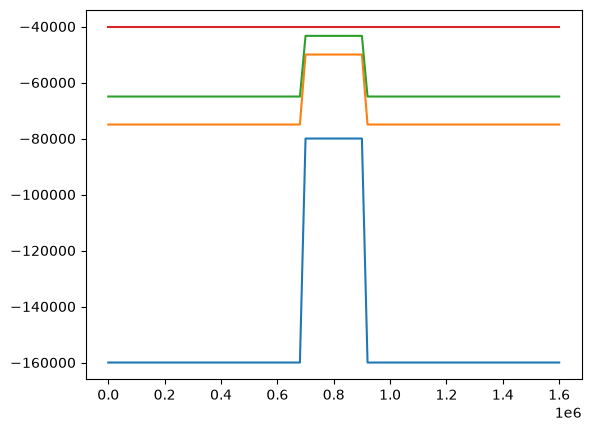

In [5]:
plt.plot(surf_lab[:,0],surf_lab[:,1])
plt.plot(surf_lm[:,0],surf_lm[:,1])
plt.plot(surf_lc[:,0],surf_lc[:,1])
plt.plot(surf_top[:,0],surf_top[:,1])


In [6]:
p_uc =  DEFAULT_MATERIALS['WET_QUARTZ'].copy()
p_uc['H']=4.8e-10 # W/kg
p_uc['friction_angle_max'] = 20.0
p_uc['friction_angle_min'] = 5.0
p_uc['cohesion_min'] = 1.0e6 # Pa

p_top = p_uc.copy()


p_lc = DEFAULT_MATERIALS['WET_ANORTHITE'].copy()
p_lc['rho'] = 2800.0
p_lc['C'] = 1.0
p_lc['friction_angle_max'] = 20.0
p_lc['friction_angle_min'] = 5.0
p_lc['cohesion_min'] = 5.0e6 # Pa

p_sed = DEFAULT_MATERIALS['WET_QUARTZ'].copy()
p_sed['rho'] = 2400.0 # kg/m3
p_sed['friction_angle_min'] = 5.0
p_sed['cohesion_min'] = 5.0e6 # Pa
p_sed['cohesion_max'] = 10.0e6 # Pa
p_sed['H'] = 5.417e-10 # W/kg
p_sed['k'] = 0.7e-6

p_lm = DEFAULT_MATERIALS['DRY_OLIVINE'].copy()
p_ast = DEFAULT_MATERIALS['WET_OLIVINE'].copy()

p_lm['k'] = p_ast['k'] = 1.2e-6
p_lm['friction_angle_max'] = p_ast['friction_angle_max'] = 20.0
p_lm['friction_angle_min'] = p_ast['friction_angle_min'] = 5.0
p_lm['cohesion_min'] = p_ast['cohesion_min'] = 5e6

p_air = DEFAULT_MATERIALS['AIR'].copy()
p_water = DEFAULT_MATERIALS['AIR'].copy()
p_water['rho'] = 1000.0

In [7]:
scen.create_interface(0,surf_lab,interface_name='asthenosphere',**p_ast)
scen.create_interface(1,surf_lm, interface_name='lithospheric_mantle',**p_lm)
scen.create_interface(2,surf_lc, interface_name='lower_crust',**p_lc)
scen.create_interface(3,surf_lc, interface_name='upper_crust',**p_uc)
scen.create_interface(4,surf_top, interface_name='basement',**p_uc)
scen.create_interface(5,surf_top, interface_name=f'water',**p_water)
scen.create_interface(-1, 0.0, interface_name='air',**p_air)

scen.create_materials_fields()

ID 0 -> asthenosphere
C:1.0; rho:3378.0; H:0.0; A:1.393e-14; n:3.0; Q:429000.0; V:1.45e-05; k:1.2e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a line
ID 1 -> lithospheric_mantle
C:1.0; rho:3354.0; H:9e-12; A:2.417e-15; n:3.5; Q:540000.0; V:2.45e-05; k:1.2e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a line
ID 2 -> lower_crust
C:1.0; rho:2800.0; H:7.123e-11; A:3.9810717e-16; n:3.0; Q:356000.0; V:0.0; k:1.15e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:25000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a line
ID 3 -> upper_crust
C:1.0; rho:2700.0; H:4.8e-10; A:8.574e-28; n:4.0; Q:222000.0; V:0.0; k:1e-06; weakening_seed:-1.0; cohesion_min:1000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a line
ID 4 

<xarray.DataTree>
Group: /
├── Group: /fields
│       Dimensions:             (z: 401, x: 1601)
│       Coordinates:
│         * z                   (z) float64 3kB -4e+05 -3.99e+05 ... -1e+03 0.0
│         * x                   (x) float64 13kB 0.0 1e+03 2e+03 ... 1.599e+06 1.6e+06
│       Data variables: (12/13)
│           rho                 (z, x) float64 5MB 3.378e+03 3.378e+03 ... 1.0 1.0
│           C                   (z, x) float64 5MB 1.0 1.0 1.0 1.0 ... 0.1 0.1 0.1 0.1
│           H                   (z, x) float64 5MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
│           A                   (z, x) float64 5MB 1.393e-14 1.393e-14 ... 1e-18 1e-18
│           n                   (z, x) float64 5MB 3.0 3.0 3.0 3.0 ... 1.0 1.0 1.0 1.0
│           Q                   (z, x) float64 5MB 4.29e+05 4.29e+05 ... 0.0 0.0
│           ...                  ...
│           k                   (z, x) float64 5MB 1.2e-06 1.2e-06 ... 1e-05 1e-05
│           weakening_seed      (z, x) float64 5MB -1.0 -1.0 -1.0 ... -1.0 -1.0 -1.0
│           cohesion_min        (z, x) float64 5MB 5e+06 5e+06 5e+06 ... 1e+05 1e+05
│           cohesion_max        (z, x) float64 5MB 2e+07 2e+07 2e+07 ... 1e+06 1e+06
│           friction_angle_min  (z, x) float64 5MB 5.0 5.0 5.0 5.0 ... 2.0 2.0 2.0 2.0
│           friction_angle_max  (z, x) float64 5MB 20.0 20.0 20.0 20.0 ... 5.0 5.0 5.0
│       Attributes:
│           description:  This group contains the fields of the model, each variable ...
└── Group: /interfaces
        Dimensions:              (x: 1601)
        Coordinates:
          * x                    (x) float64 13kB 0.0 1e+03 2e+03 ... 1.599e+06 1.6e+06
        Data variables:
            air                  (x) float64 13kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
            asthenosphere        (x) float64 13kB -1.6e+05 -1.6e+05 ... -1.6e+05
            lithospheric_mantle  (x) float64 13kB -7.5e+04 -7.5e+04 ... -7.5e+04
            lower_crust          (x) float64 13kB -6.5e+04 -6.5e+04 ... -6.5e+04
            upper_crust          (x) float64 13kB -6.5e+04 -6.5e+04 ... -6.5e+04
            basement             (x) float64 13kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
            water                (x) float64 13kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
        Attributes:
            description:  This group contains the interfaces of the model, each inter...

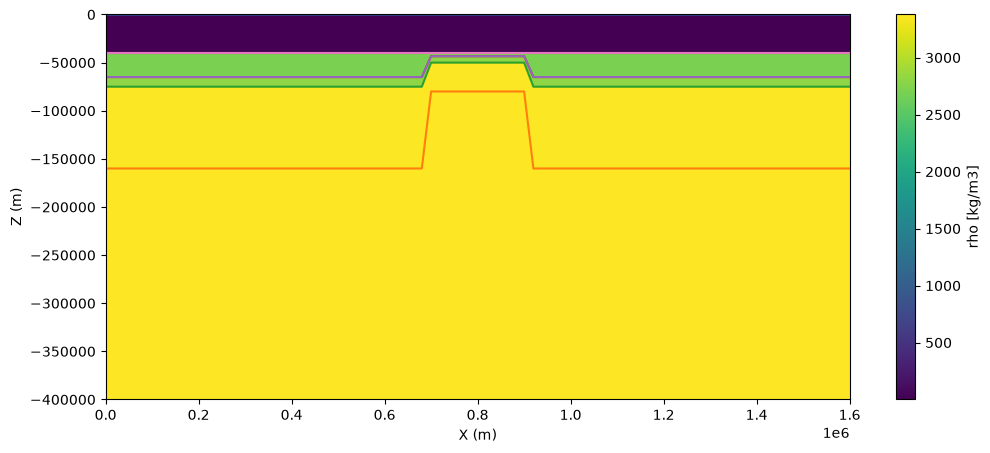

In [8]:
plt.figure(figsize=(12,5))

scen.DTree.fields.rho.plot.pcolormesh(x='x')
for ds in scen.DTree.interfaces.values():
    ds.plot(x='x',label=f'({ds.attrs["id"]:02d}) {ds.name}')


plt.xlabel('X (m)')
plt.ylabel('Z (m)')
plt.xlim(0,scen.Lx)
plt.ylim(scen.Lz,0)
scen.DTree

Velocity is given in cm/y. The field will be automatically converted to m/s
The velocity builder was created.
(set) velocity in the right: from [-180000.0,-30000.0], vx=5.000e-01, vz=0.000e+00 cm/y
Int V = 2.392e-05 m²/s
v_ast = -1.3389 cm/y
linear velocity in the right boundary: vx = 8.359e-06 * COORD + 2.005e+00
(set) velocity in the left: from [-180000.0,-30000.0], vx=-5.000e-01, vz=0.000e+00 cm/y
linear velocity in the left boundary: vx = -8.359e-06 * COORD + -2.005e+00
Int V = -1.079e-05 m²/s
(add) velocity in the top: from [1500.0,1598500.0], vx=0.000e+00, vz=1.066e-02 cm/y
Int V = -5.396e-06 m²/s
(add) velocity in the bot: from [1500.0,1598500.0], vx=0.000e+00, vz=-5.331e-03 cm/y
Int V = -2.698e-06 m²/s
(add) velocity in the top: from [1500.0,1598500.0], vx=0.000e+00, vz=2.666e-03 cm/y
Int V = -1.349e-06 m²/s
(add) velocity in the bot: from [1500.0,1598500.0], vx=0.000e+00, vz=-1.333e-03 cm/y
Int V = -6.745e-07 m²/s
(add) velocity in the top: from [1500.0,1598500.0], vx=0.000e+0

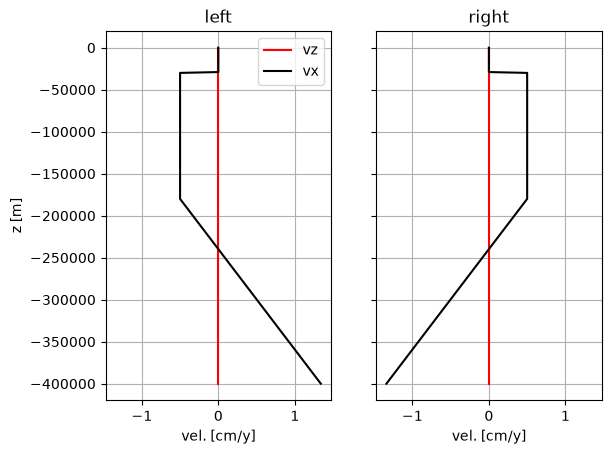

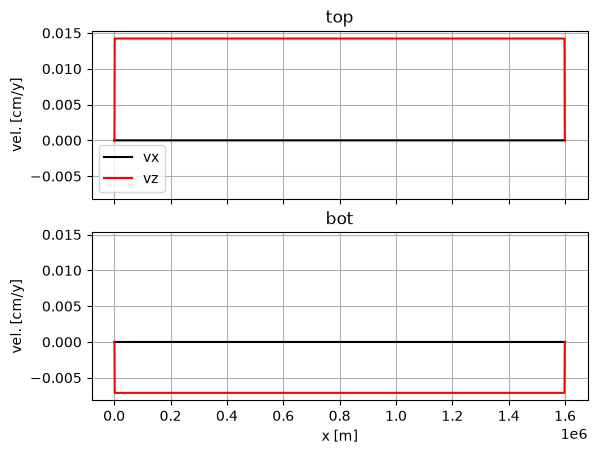

In [9]:
ast_range = 20e3 #m
air_range = 10e3 #m

# creating the velocity builder
velocbuild = VelocityFieldBuilder(scen)

# constant velocity in the lithosphere
velocbuild.set_region('right',[(d_ast-ast_range),(d_top+air_range)],vx=v_rift, vz=0) # constant velocity in the right


int_out = velocbuild.integrate_normal_components()*velocbuild.unifac_int # integral of outflux cm²/y 
in_range = ((d_ast-ast_range)-(-lz+t_air))*100 # cm

v_ast = (-2*int_out / in_range)-v_rift  # asthenospheric normal velocity in z=Lz
print(f'v_ast = {v_ast:.4f} cm/y')

velocbuild.linear_velocity('right','vx',range=[scen.Lz,(d_ast-ast_range)],
                           clims=[scen.Lz,(d_ast-ast_range)],
                           vlims=[v_ast,v_rift])


velocbuild.set_region('left',[(d_ast-ast_range),(d_top+air_range)],vx=-v_rift, vz=0) # constant velocity in the left
velocbuild.linear_velocity('left','vx',range=[scen.Lz,(d_ast-ast_range)],
                           clims=[scen.Lz,(d_ast-ast_range)],
                           vlims=[-v_ast,-v_rift])


# keeping the velocity field conservative
for i in range(10):
    velocbuild.conservate_veloc('top',0.5)
    velocbuild.conservate_veloc('bot',0.5)

lr, bt = velocbuild.view_veloc()
lr.savefig(os.path.join(scen.path,'v_lr.png'),bbox_inches='tight')
bt.savefig(os.path.join(scen.path,'v_bt.png'),bbox_inches='tight')

scen.create_velocity_field(velocbuild)

In [10]:
tempbuild = TemperatureFieldBuilder(scen,LAB_interface=0,surface_interface=5,c_cap=1250,g=-10,alpha = 0.0000328)
tempbuild.apply_linear_temperature(t_pot=1350)

/home/jobueno/miniconda3/envs/tapioca/lib/python3.14/site-packages/IPython/core/events.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


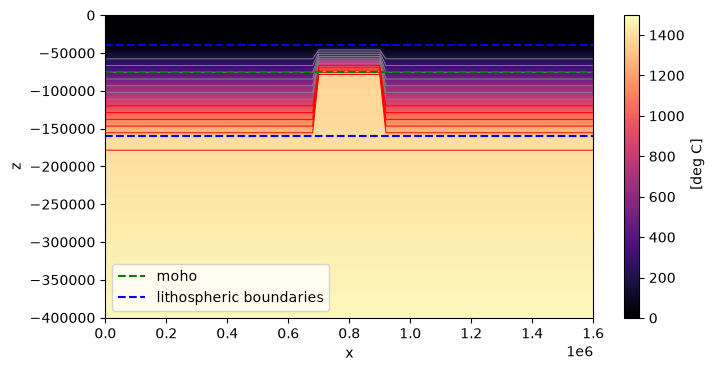

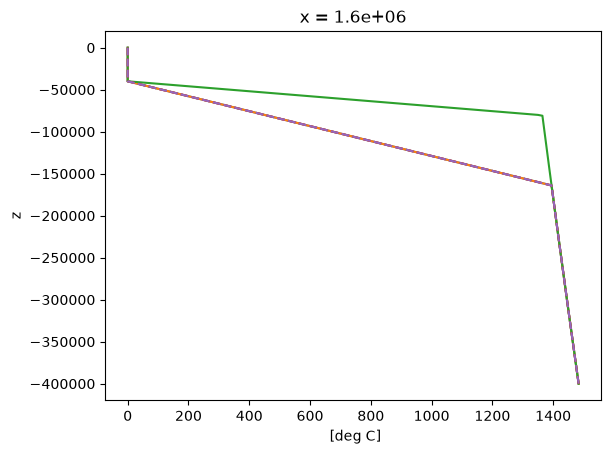

In [11]:
plt.figure(figsize=(20,10,'cm'))
tempbuild.temperature.plot(y='z',vmin=0,vmax=1500,cmap='magma')
tempbuild.temperature.plot.contour(y='z',colors='gray',levels=np.arange(200,801,100),lw=0.7)
tempbuild.temperature.plot.contour(y='z',colors='red',levels=np.arange(900,1600,100),lw=0.7)

plt.axhline(d_top,color='blue',ls='--',lw=1.5)
plt.axhline(d_lm,color='green',ls='--',lw=1.5,label='moho')
plt.axhline(d_ast,color='blue',ls='--',lw=1.5,label='lithospheric boundaries')
plt.legend()

plt.figure()
tempbuild.temperature[:,0].plot(y='z')
tempbuild.temperature[:,400].plot(y='z')
tempbuild.temperature[:,800].plot(y='z')
tempbuild.temperature[:,1200].plot(y='z',ls='--')
tempbuild.temperature[:,1600].plot(y='z',ls='--')

Solving the 2D heat equation
Diagonals prepared


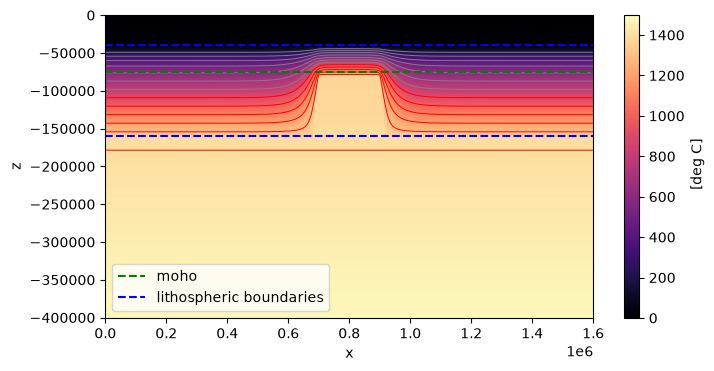

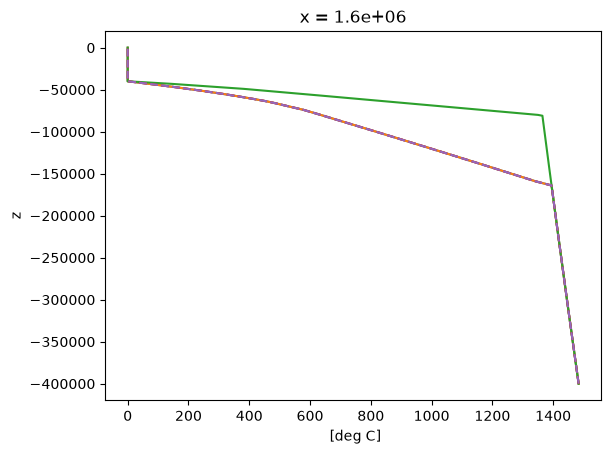

In [12]:
tempbuild.solve_heat_2D(bot_bc='adiabatic')

plt.figure(figsize=(20,10,'cm'))
tempbuild.temperature.plot(y='z',vmin=0,vmax=1500,cmap='magma')
tempbuild.temperature.plot.contour(y='z',colors='gray',levels=np.arange(200,801,100),lw=0.7)
tempbuild.temperature.plot.contour(y='z',colors='red',levels=np.arange(900,1600,100),lw=0.7)

plt.axhline(d_top,color='blue',ls='--',lw=1.5)
plt.axhline(d_lm,color='green',ls='--',lw=1.5,label='moho')
plt.axhline(d_ast,color='blue',ls='--',lw=1.5,label='lithospheric boundaries')
plt.legend()

plt.figure()
tempbuild.temperature[:,0].plot(y='z')
tempbuild.temperature[:,400].plot(y='z')
tempbuild.temperature[:,800].plot(y='z')
tempbuild.temperature[:,1200].plot(y='z',ls='--')
tempbuild.temperature[:,1600].plot(y='z',ls='--')

In [13]:
scen.create_temperature_field(tempbuild)

Temperature field was created in the scenario builder.


In [14]:
scen.calculate_YSE(sr=1e-15)

Using thermal expansion coefficient used in the `TemperatureFieldBuilder`: alpha=3.28e-05
Lithostatic pressure was calculated.
Plastic rheology: Druker-Prager Criterion
Viscous rheology: dislocation creep
Yield Strength Envelopte was calculated.


In [15]:
colors = {'air':"#ffffff",
 'asthenosphere':"#81a75e",
 'lithospheric_mantle':"#587240",
 'lower_crust':"#c2a886",
 'upper_crust':"#717ea1",
 'basement':"#717ea1"}

colors['bot_weak_seed'] = colors['lithospheric_mantle']
colors['top_weak_seed'] = "#1C2414"

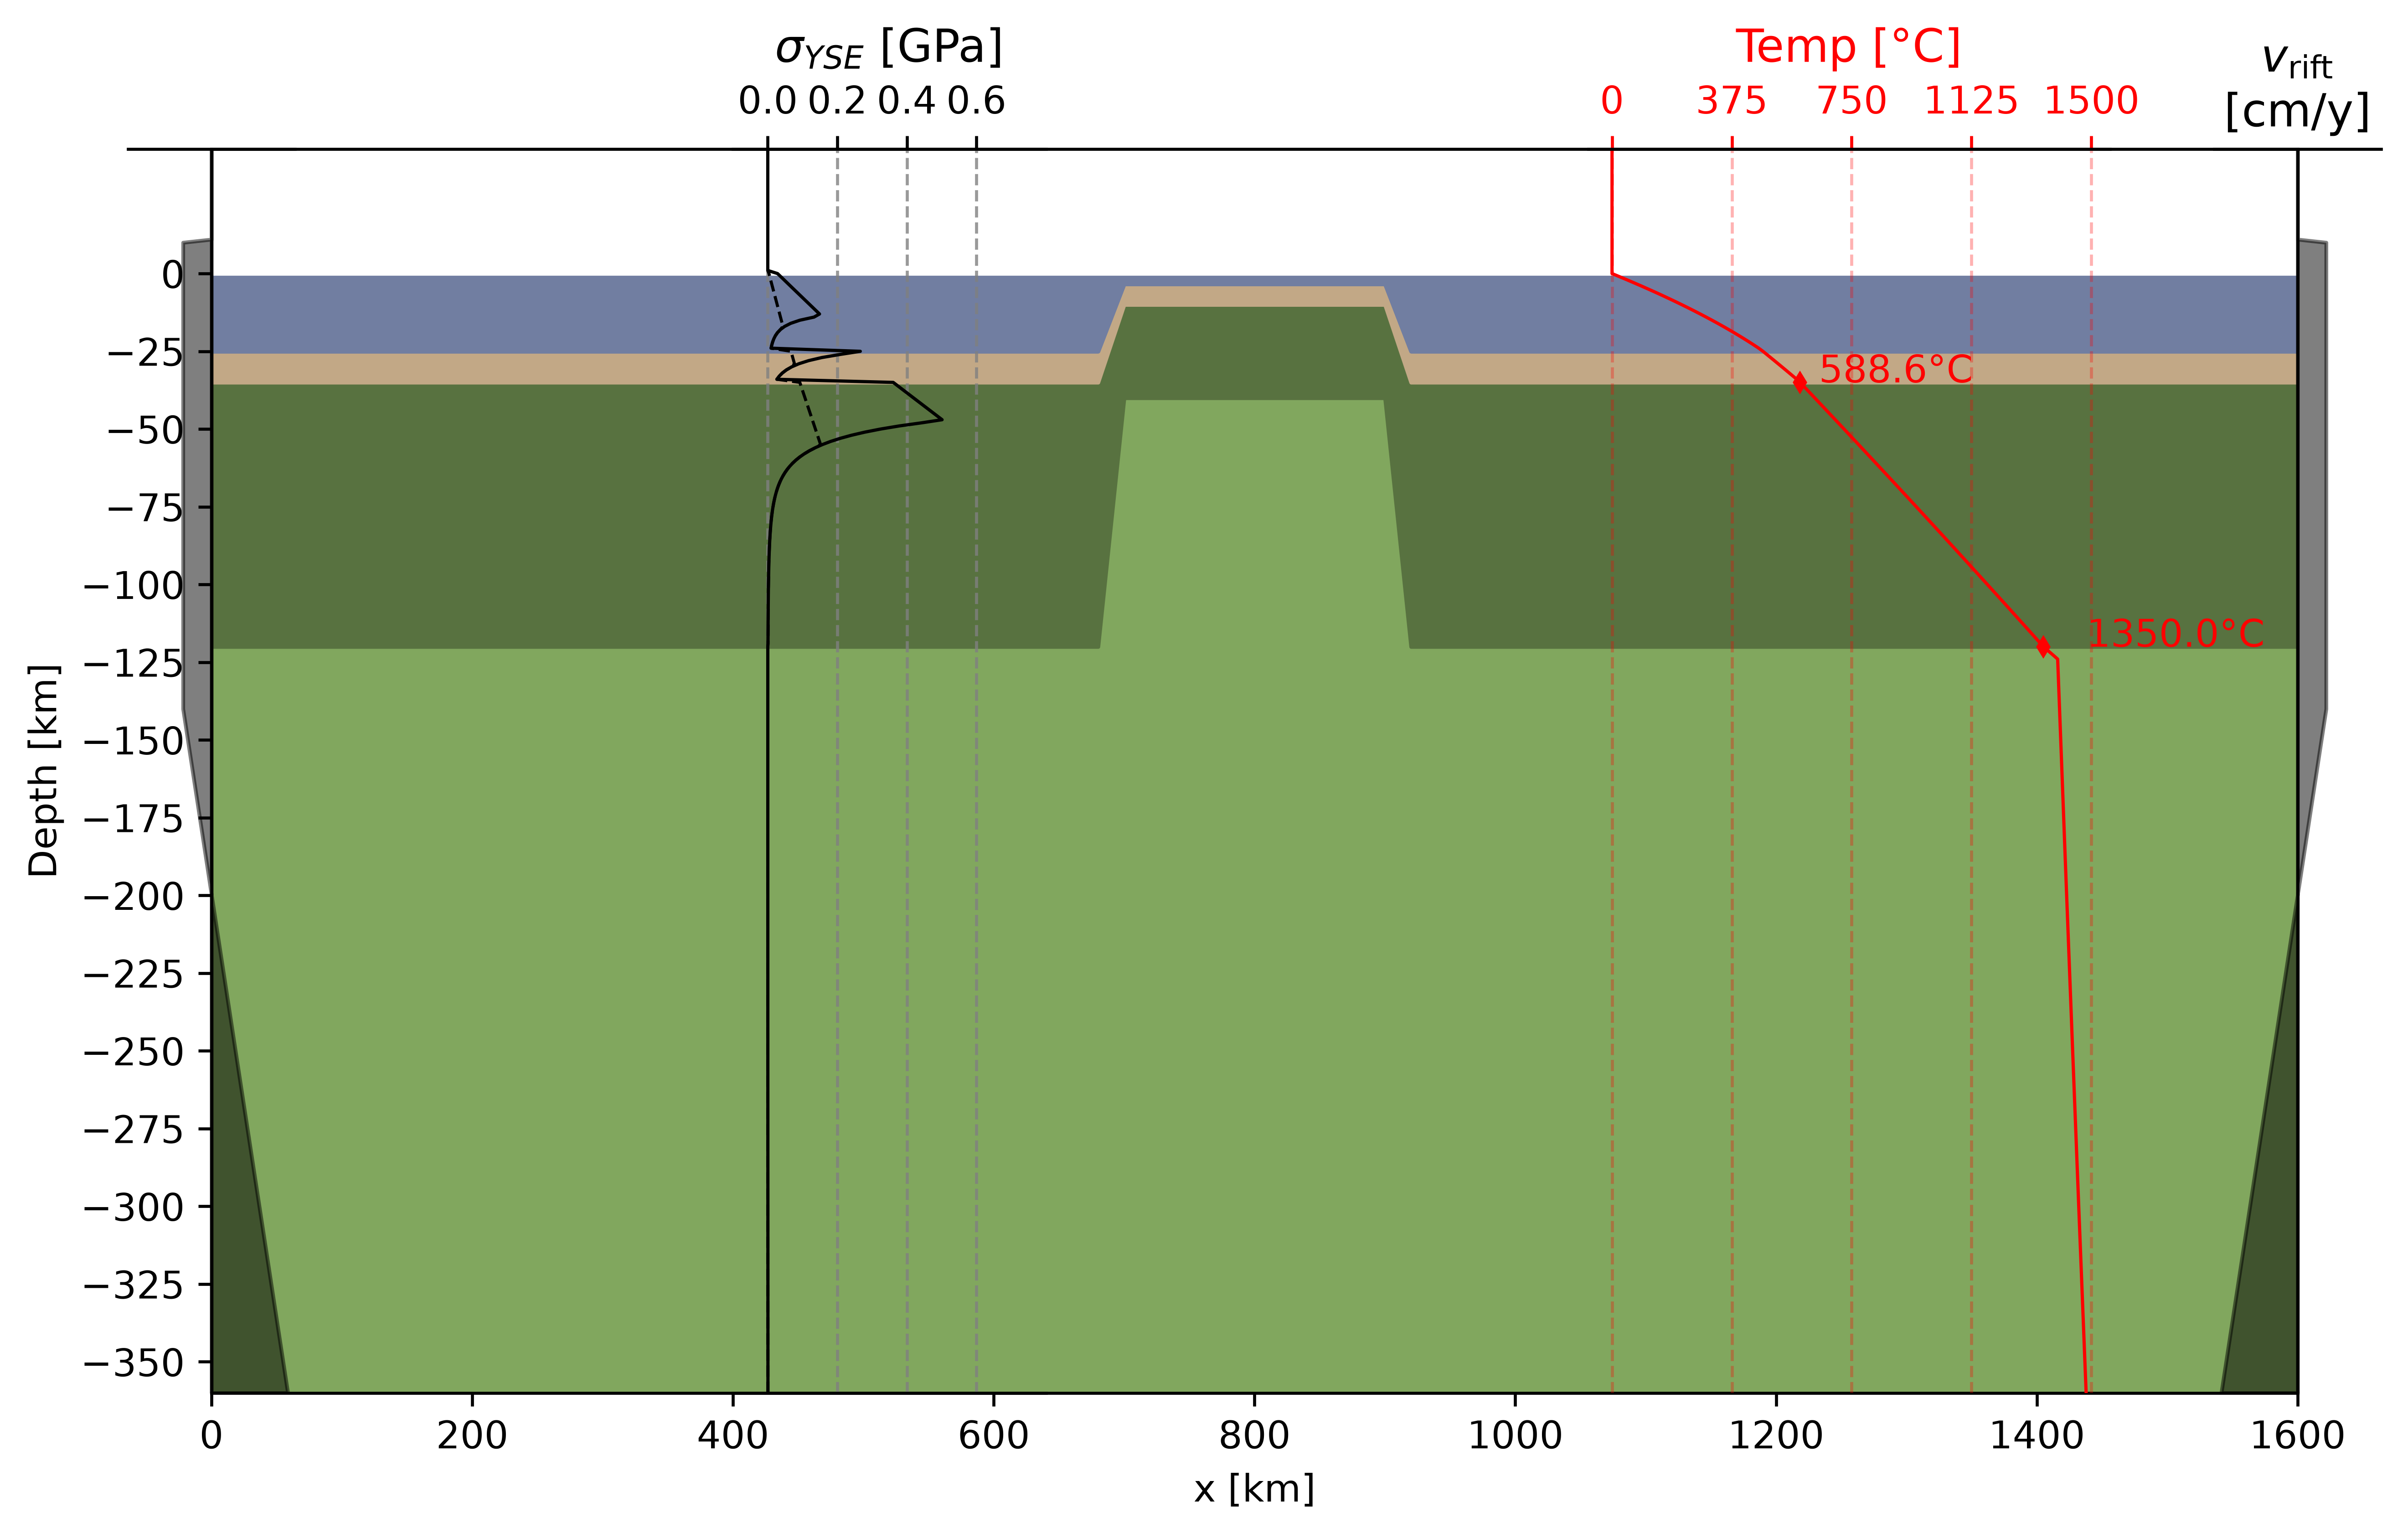

In [16]:
fig, ax = plt.subplots(figsize=(25, 15,'cm'),dpi=600)
ylimplot = [(-lz+t_air)/1e3, (0 + t_air)/1e3]

inx_profiles = 200

interfaces = scen.DTree.interfaces
interfaces_list = list(interfaces.data_vars)

xplot = scen.DTree.fields.x/1e3
zplot = (scen.DTree.fields.z+t_air)/1e3

#asthenosphere
ax.fill_between(xplot, (-lz + t_air)/1e3, 
                (interfaces[interfaces_list[1]].values+ t_air)/1e3, 
                color=colors.get('asthenosphere',None),label='asthenosphere')

for i in range(2,len(interfaces_list)):
    ci_name = interfaces_list[i]
    pi_name = interfaces_list[i-1]

    cint = interfaces[ci_name].values + t_air
    pint = interfaces[pi_name].values + t_air
    
    ax.fill_between(xplot, cint/1e3, pint/1e3, color=colors.get(ci_name,None),label=ci_name)#.get(label,None))

#air
ax.fill_between(xplot, (interfaces[interfaces_list[-1]].values+ t_air)/1e3, 
                (interfaces[interfaces_list[0]].values+ t_air)/1e3, 
                color=colors.get('air',None),label='air')


ax.set_yticks(np.arange(-lz/1e3, 1, 25))

ax.set_xlim([0, lx/1e3])
ax.set_ylim(ylimplot)

ax.set_xlabel("x [km]")
ax.set_ylabel("Depth [km]")

# plt.title("Interfaces")

MS_CMY = 100*365.25*24*3600

velx = scen.DTree.fields.vx
fac = 0.96
# Velocity = Right side
vr = velx.isel(x=-1)
vr_plot = np.max(abs(vr))*MS_CMY + 0.125

axr = ax.inset_axes((fac,0,(1-fac)*2,1))
axr.fill_betweenx(zplot, vr*MS_CMY, 0, color='k', facecolor='k', hatch=None,alpha=0.5)
axr.set_ylim(ylimplot)
axr.set_yticks([])
axr.set_xticks([])
axr.patch.set_alpha(0)
axr.xaxis.set_ticks_position('top')
axr.tick_params(labelbottom=False,labeltop=True)
axr.set_xlim([-vr_plot,vr_plot])
axr.spines['left'].set_visible(False)
axr.spines['right'].set_visible(False)
axr.spines['bottom'].set_visible(False)
axr.set_title("$v_{\\text{rift}}$\n[cm/y]")

# Velocity = Left side
vl = velx.isel(x=0)
vl_plot = np.max(abs(vl))*MS_CMY + 0.125

axl = ax.inset_axes((-(1-fac),0,(1-fac)*2,1))
axl.fill_betweenx(zplot, 0, vl*MS_CMY, color='k', facecolor='k', hatch=None,alpha=0.5)
axl.set_ylim(ylimplot)
axl.set_yticks([])
axl.set_xticks([])
axl.patch.set_alpha(0)
axl.xaxis.set_ticks_position('top')
axl.tick_params(labelbottom=False,labeltop=True)
axl.set_xlim([-vl_plot, vl_plot])
axl.spines['left'].set_visible(False)
axl.spines['right'].set_visible(False)
axl.spines['bottom'].set_visible(False)

# Temperature
temp_prof = scen.DTree.fields.temperature.isel(x=inx_profiles)
T_moho = temp_prof.interp(z=d_lm)
T_lab = temp_prof.interp(z=d_ast)

axt = ax.inset_axes((3.3/5,0,0.25,1))
axt.plot(temp_prof.values, zplot, "-r",lw=0.85)
axt.grid(visible=True, axis='x',which='both',ls='--',color='red',alpha=0.3)
axt.set_ylim(ylimplot)
axt.set_yticks([])
axt.set_xticks(np.linspace(0,1500,5))
axt.patch.set_alpha(0)
axt.xaxis.set_ticks_position('top')
axt.set_yticks([])
axt.xaxis.label.set_color('red')
axt.tick_params(axis='x', colors='red')
axt.spines['left'].set_visible(False)
axt.spines['right'].set_visible(False)
axt.set_title('Temp [°C]',color='red')
axt.spines['bottom'].set_visible(False)

# Marker in the Moho
axt.plot(T_moho,(d_lm+t_air)/1e3,'rd',ms=3.0) 
axt.annotate(f'{T_moho:.1f}°C',(T_moho*1.1,(d_lm+t_air)/1e3),color='red')

# Marker in the Moho
axt.plot(T_lab,(d_ast+t_air)/1e3,'rd',ms=3.0) 
axt.annotate(f'{T_lab:.1f}°C',(T_lab*1.1,(d_ast+t_air)/1e3),color='red')

# #yield strength envelope
YSE = scen.DTree.fields.YSE.isel(x=inx_profiles) /1e9 #GPa
YSE_soft = scen.DTree.fields.YSE_soft.isel(x=inx_profiles) /1e9 #GPa

axsg = ax.inset_axes((300/1200,0,0.15,1))
axsg.plot(YSE_soft,zplot,'k--',lw=0.8)
axsg.plot(YSE,zplot,'k',lw=0.85)

axsg.grid(visible=True, axis='x',which='both',ls='--',color='gray',alpha=0.8)
axsg.set_xticks([0,0.2,0.4,0.6])
axsg.set_xlim(-0.1,0.8)
axsg.set_ylim(ylimplot)
axsg.set_yticks([])
axsg.patch.set_alpha(0)
axsg.xaxis.set_ticks_position('top')
axsg.spines['left'].set_visible(False)
axsg.spines['right'].set_visible(False)
axsg.set_title('$\\sigma_{YSE}$ [GPa]')
    
# plt.legend(bbox_to_anchor=(0., -.31, 1., -.102), loc='lower left', ncols=3, mode="expand", borderaxespad=0.,shadow=True)

# #fig.legend(ncols=3,mode='expand',bbox_to_anchor=(0., -0.1), borderaxespad=0.)
# plt.tight_layout()
# plt.show()
fig.savefig(os.path.join(scen.path,f'interfaces.svg'),dpi=300,bbox_inches='tight')
fig.savefig(os.path.join(scen.path,f'interfaces.png'),dpi=300,bbox_inches='tight')

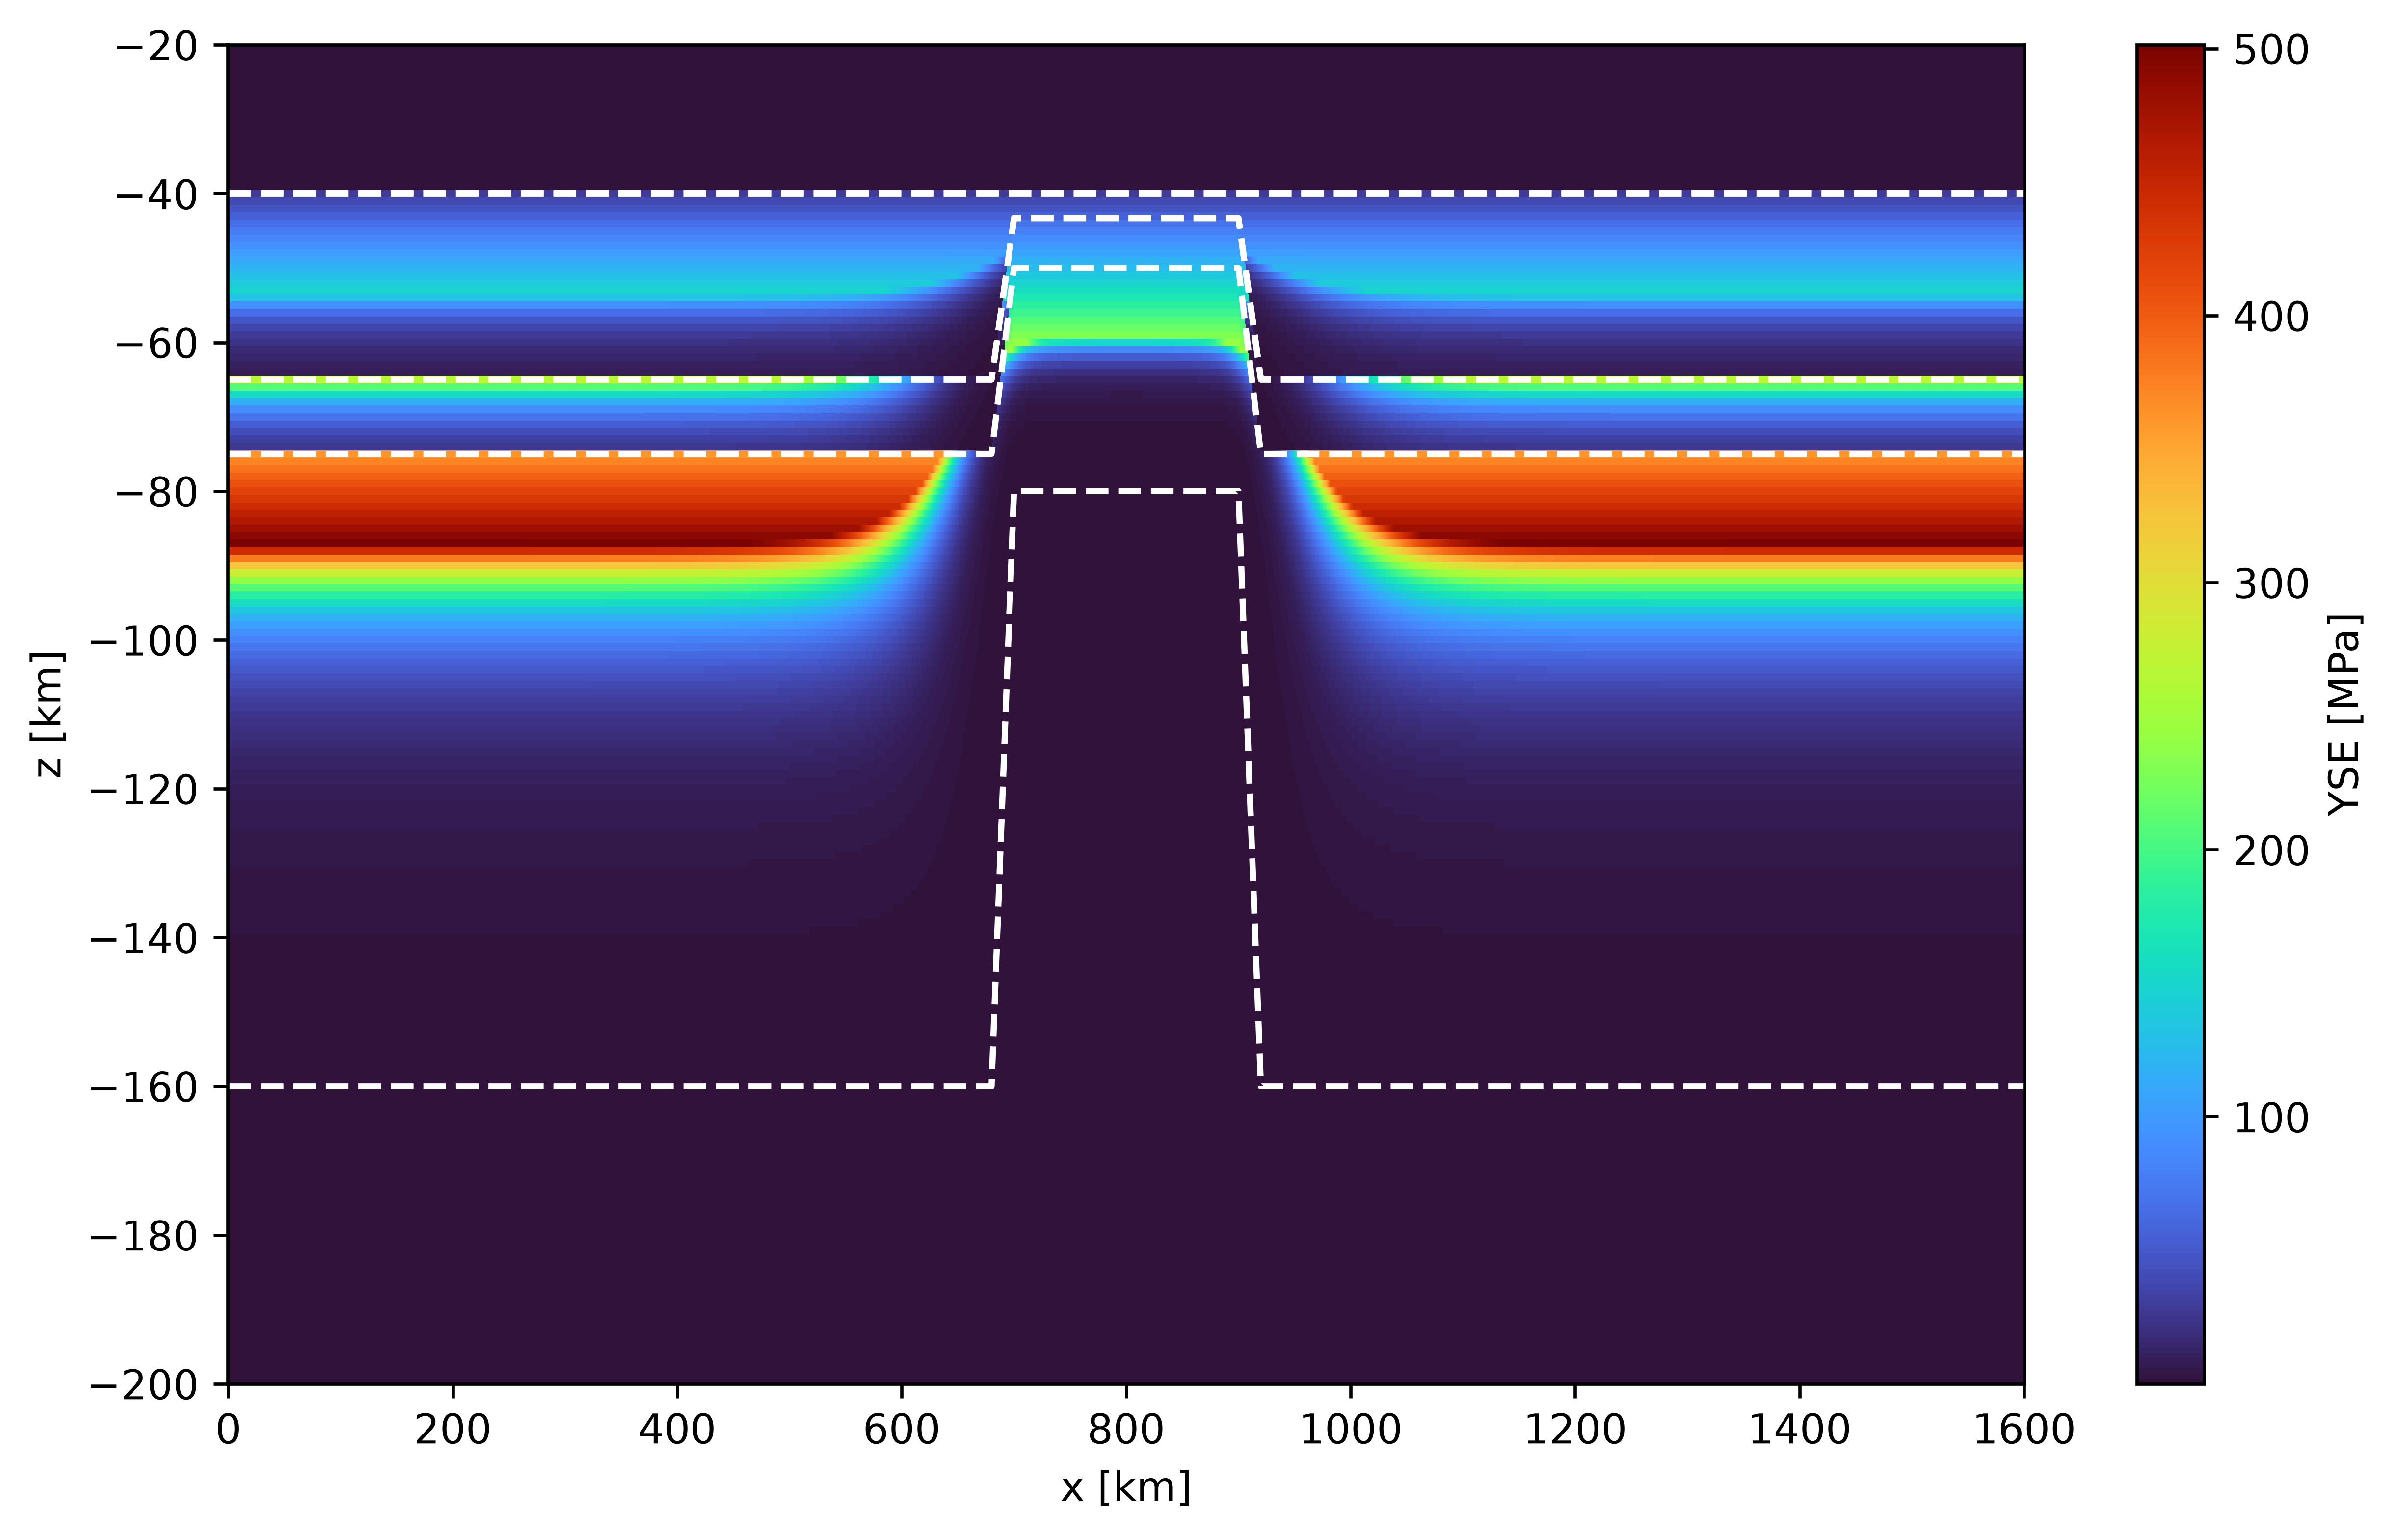

In [17]:
yse_field = scen.DTree.fields.YSE/1e6

fig, ax = plt.subplots(figsize=(25, 15,'cm'),dpi=600)
yseplot = ax.pcolormesh(scen.DTree.fields.x/1e3,scen.DTree.fields.z/1e3,yse_field, cmap='turbo',rasterized=True)

for ds in scen.DTree.interfaces.values():
    ax.plot(ds.x/1e3, ds.values/1e3,label=f'({ds.name}',color='white',ls='--')

fig.colorbar(yseplot,label='YSE [MPa]')

ax.set_ylabel('z [km]')
ax.set_xlabel('x [km]')
ax.set_ylim(-200,-20)

fig.savefig(os.path.join(scen.path,f'YSE_field.svg'),dpi=300,bbox_inches='tight')
fig.savefig(os.path.join(scen.path,f'YSE_field.png'),dpi=300,bbox_inches='tight')

In [18]:
params_dict = {   
    'particles_per_element':100,
    'particles_per_element_x':10,
    'particles_per_element_z':10,
    'particles_to_export':2,
    'particles_perturb_factor':0.7,

    ## Inputs
    'interfaces_from_ascii':True, 
    'temperature_from_ascii':True, 
    'velocity_from_ascii':True, 
    'water_interface':-1,

    ## Magmatism
    'magmatism':'off', 
    'magmatism_extraction':'off', 
    'magmatic_layer':-1, 

    ## Numerical
    'solver':'direct', 
    'denok':1.0e-15,
    'Xi_min':5.0e-6,
    'non_linear_method':'on', 

    ## Time    
    'step_max':5000,
    'step_print':20,
    'time_max':70.0e6,
    'dt_max':20.0e3,
    'sub_division_time_step':0.5,
    'initial_print_step':0,

    ## Rheology
    'initial_dynamic_range':True, 
    'viscosity_reference':1.0e21,
    'viscosity_min':1.0e18,
    'viscosity_max':1.0e25,
    'viscosity_per_element':'constant', 
    'viscosity_mean_method':'arithmetic', 
    'viscosity_dependence':'pressure', 

    'random_initial_strain':0.5,
    'rheology_model':9,
    'weakening_min':0.05,
    'weakening_max':1.05,

    # 'A_healing':float,
    # 'T0_healing':float,
    # 'k_healing':float,
    # 'strain_healing':float,

    # Temperature and other parameters
    'geoq':str,
    'geoq_fac':100, 
    'adiabatic_component':'on', 
    'shear_heating':'off', 
    # 'Xi_shear':str, 
    'radiogenic_component':'on', 
    'high_kappa_in_asthenosphere':False, 

    # 'T_initial':int,
    # 'temperature_difference':float,
    # 'external_heat':float,
    # 'basal_heat':float,
    # 'pressure_const':float,

    # Physical parameters
    'density_mantle':3300.0,
    'gravity_acceleration':10.0,
    'thermal_expansion_coefficient':3.28e-5,
    # 'thermal_diffusivity_coefficient':float,
    'heat_capacity':1250.0,

    # Surface processes
    'sp_surface_tracking':True, 
    'surface_particles_per_element':50,
    'sp_surface_processes':False, 

    'free_surface_stab':True, 
    'theta_FSSA':0.5,
    
    'sp_mode':'none',
    'sticky_blanket_air':True, 
    
    # 'surface_velocity':float,
    # 'strain_sed':float,
    'a2l':True, 

    ## Fluvial/diffusion
    # 'K_fluvial':float,
    # 'm_fluvial':float,
    # 'sea_level':float,
    # 'sp_d_c':float,

    ## Submarine
    # 'continental_slope':float,
    # 'variable_base_level':str,
    
    # Boundary conditions
    
    'top_normal_velocity':'fixed', 
    'bot_normal_velocity':'fixed', 
    'left_normal_velocity':'fixed', 
    'right_normal_velocity':'fixed',  
    
    'top_tangential_velocity':'fixed', 
    'bot_tangential_velocity':'free', 
    'left_tangential_velocity':'free', 
    'right_tangential_velocity':'free', 
    
    'top_temperature':'fixed', 
    'bot_temperature':'fixed', 
    'left_temperature':'free', 
    'right_temperature':'free', 

    'variable_bcv':False, 
    'bcv_extern':False,   
    'multi_velocity':False,  

    # Outputs
    'export_thermal_diffusivity':True,
    'print_step_files':True, 
    'export_lithology':True
}
scen.set_params(**params_dict)

gravity_acceleration was already set in the builder.
thermal_expansion_coefficient was already set in the builder.
heat_capacity was already set in the builder.
